# Results analysis

Analyse the saved 2025 test results without retraining models. Overall metrics weight airports equally. Figures are exported as PDF and PNG.

The historical-data reference includes the target airport's 2024 flights and therefore has more training data. Its advantage does not isolate airport familiarity from training-set size.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS_DIR = PROJECT_ROOT / "outputs/final_evaluation"
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

results = pd.read_csv(RESULTS_DIR / "airport_results.csv")
reference_intervals = pd.read_csv(RESULTS_DIR / "reference_ap_intervals.csv")
weather_intervals = pd.read_csv(RESULTS_DIR / "weather_ap_intervals.csv")
FAMILIES = {"logistic": "Logistic regression", "forest": "Random forest", "xgboost": "XGBoost"}
METRICS = ["average_precision", "roc_auc", "log_loss"]
airports = sorted(results["airport"].unique())

plt.rcParams.update({"font.size": 10, "figure.dpi": 120, "savefig.dpi": 300})

def save_figure(fig, name):
    for extension in ["pdf", "png"]:
        fig.savefig(FIGURE_DIR / f"{name}.{extension}", bbox_inches="tight")


## Validate saved results

In [2]:
keys = ["airport", "family", "variant", "condition"]
assert len(airports) == 10 and len(results) == 180
assert not results.duplicated(keys).any()
assert set(results["family"]) == set(FAMILIES)
assert set(results["variant"]) == {"flight_only", "weather"}
assert set(results["condition"]) == {"constant", "unseen", "reference"}
assert results.groupby("airport")["flights"].nunique().eq(1).all()
assert np.isfinite(results[METRICS].to_numpy()).all()

ap = results.pivot(index=["airport", "family", "variant"], columns="condition", values="average_precision")
weather_ap = results.loc[results["condition"].eq("unseen")].pivot(
    index=["airport", "family"], columns="variant", values="average_precision"
)
for frame, index, expected in [
    (reference_intervals, ["airport", "family", "variant"], ap["reference"] - ap["unseen"]),
    (weather_intervals, ["airport", "family"], weather_ap["weather"] - weather_ap["flight_only"]),
]:
    assert not frame.duplicated(index).any()
    actual = frame.set_index(index).sort_index()
    expected = expected.sort_index()
    assert actual.index.equals(expected.index)
    assert np.allclose(actual["ap_difference"], expected)
    assert actual["ci_lower"].le(actual["ci_upper"]).all()
    assert actual["bootstrap_repetitions"].eq(1000).all()

print("Validated 180 metric rows, 60 reference intervals and 30 weather intervals.")

Validated 180 metric rows, 60 reference intervals and 30 weather intervals.


## Overall model performance

Points show equal-airport means, not pooled-flight metrics. No uncertainty intervals for these overall means have been calculated. Higher AP and ROC-AUC are better; lower log loss is better.

average_precision  roc_auc  log_loss
family   variant     condition                                      
forest   flight_only constant              0.2325   0.5000    0.5430
                     reference             0.3595   0.6554    0.5170
                     unseen                0.3547   0.6511    0.5190
         weather     constant              0.2325   0.5000    0.5430
                     reference             0.3706   0.6646    0.5138
                     unseen                0.3640   0.6582    0.5161
logistic flight_only constant              0.2325   0.5000    0.5430
                     reference             0.3566   0.6540    0.5172
                     unseen                0.3523   0.6503    0.5199
         weather     constant              0.2325   0.5000    0.5430
                     reference             0.3722   0.6663    0.5119
                     unseen                0.3680   0.6629    0.5151
xgboost  flight_only constant              0.2325   0.5000    0.5430
                     reference             0.3619   0.6583    0.5145
                     unseen                0.3563   0.6527    0.5174
         weather     constant              0.2325   0.5000    0.5430
                     reference             0.3797   0.6733    0.5078
                     unseen                0.3688   0.6644    0.5124

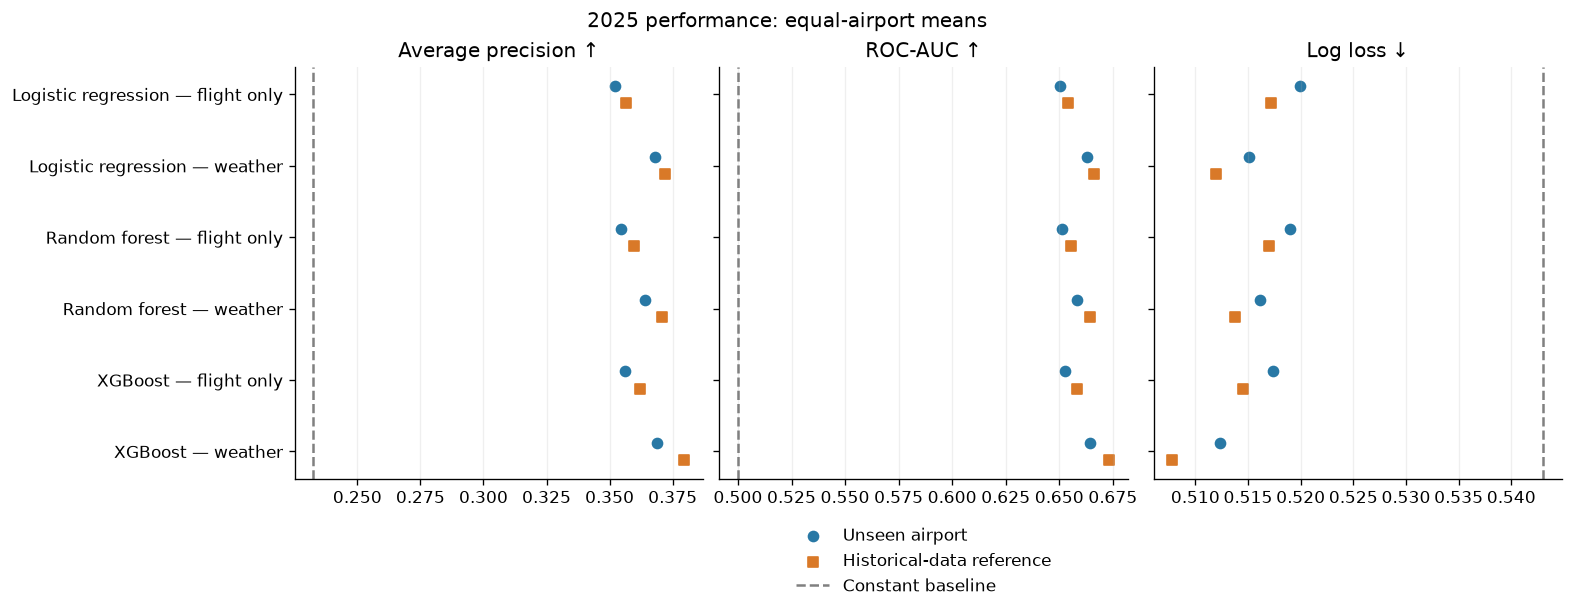

In [3]:
overall = results.groupby(["family", "variant", "condition"])[METRICS].mean()
display(overall.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True, layout="constrained")
combinations = [(f, v) for f in FAMILIES for v in ["flight_only", "weather"]]
labels = [f"{FAMILIES[f]} — {'weather' if v == 'weather' else 'flight only'}" for f, v in combinations]
for ax, metric, title in zip(axes, METRICS, ["Average precision ↑", "ROC-AUC ↑", "Log loss ↓"]):
    for condition, offset, color, marker, label in [
        ("unseen", -0.12, "#2878A5", "o", "Unseen airport"),
        ("reference", 0.12, "#D97928", "s", "Historical-data reference"),
    ]:
        values = [overall.loc[(f, v, condition), metric] for f, v in combinations]
        ax.scatter(values, np.arange(6) + offset, color=color, marker=marker, label=label)
    baseline = results.loc[results["condition"].eq("constant")].drop_duplicates("airport")[metric].mean()
    ax.axvline(baseline, color="grey", linestyle="--", label="Constant baseline")
    ax.set_title(title)
    ax.set_yticks(range(6), labels)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
fig.suptitle("2025 performance: equal-airport means")
save_figure(fig, "overall_model_performance")
plt.show()

## Paired AP differences by airport

Dots are observed differences; horizontal bars are individual, unadjusted 95% percentile intervals from 1,000 paired day-bootstrap samples. Days are sampled with replacement and the same sampled flights are used for both models. AP is calculated across flights, not averaged across daily AP values.

These intervals condition on fitted models. They do not include training variability or preserve dependence between consecutive days. An interval containing zero does not demonstrate equivalence.

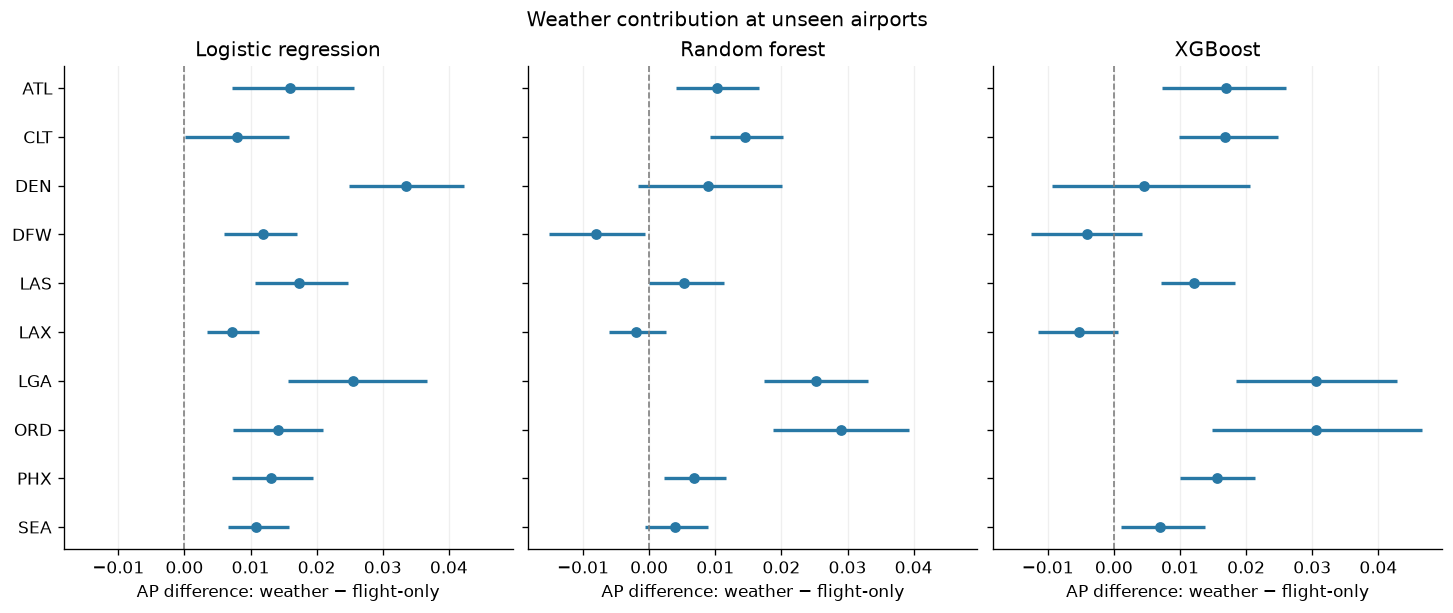

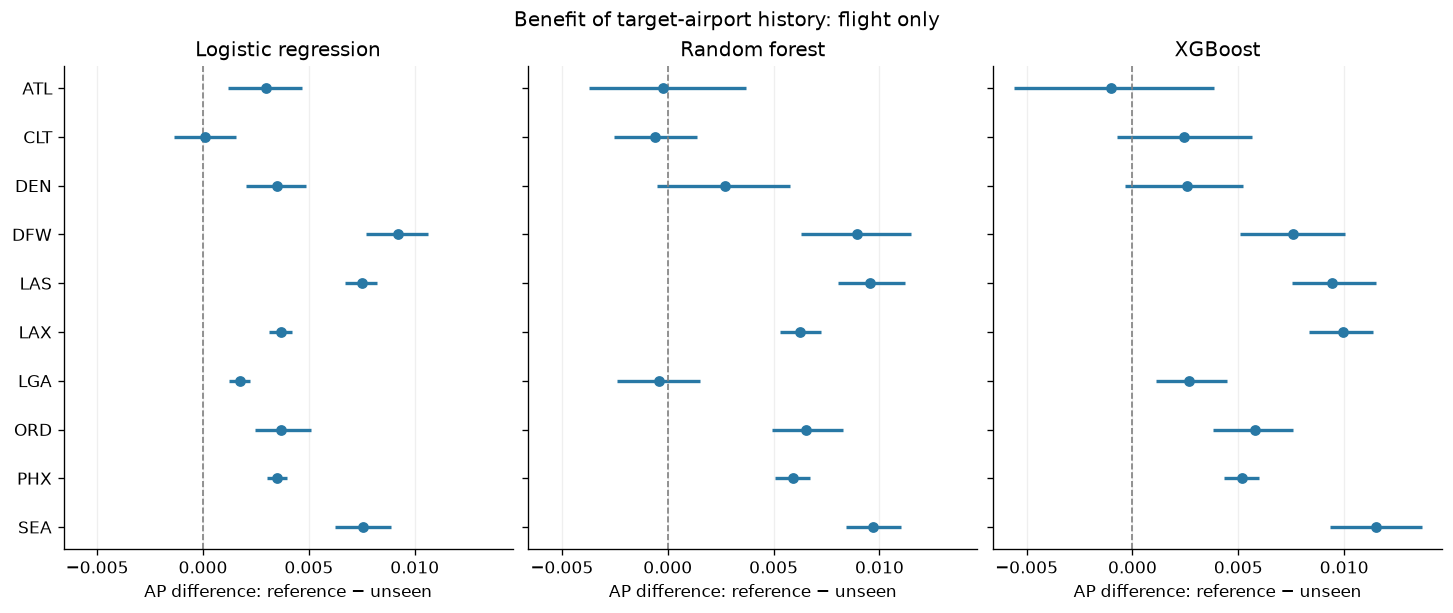

In [ ]:
def plot_intervals(frame, title, xlabel, filename):
    fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharex=True, sharey=True, layout="constrained")
    for ax, (family, label) in zip(axes, FAMILIES.items()):
        subset = frame.loc[frame["family"].eq(family)].set_index("airport").loc[airports]
        y = np.arange(len(airports))
        ax.hlines(y, subset["ci_lower"], subset["ci_upper"], color="#2878A5", linewidth=2)
        ax.scatter(subset["ap_difference"], y, color="#2878A5", s=30, zorder=3)
        ax.axvline(0, color="grey", linestyle="--", linewidth=1)
        ax.set_title(label)
        ax.set_xlabel(xlabel)
        ax.set_yticks(y, airports)
        ax.grid(axis="x", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].invert_yaxis()
    fig.suptitle(title)
    save_figure(fig, filename)
    plt.show()

plot_intervals(
    weather_intervals, "Weather contribution at unseen airports",
    "AP difference: weather − flight-only", "weather_ap_intervals",
)
for variant in ["flight_only", "weather"]:
    plot_intervals(
        reference_intervals.loc[reference_intervals["variant"].eq(variant)],
        f"Benefit of target-airport history: {variant.replace('_', ' ')}",
        "AP difference: reference − unseen", f"reference_ap_intervals_{variant}",
    )

## Descriptive interval summaries

Counts below describe individual intervals, not a simultaneous significance claim across comparisons.

In [ ]:
def interval_summary(frame, grouping):
    classified = frame.assign(
        above_zero=frame["ci_lower"].gt(0),
        below_zero=frame["ci_upper"].lt(0),
        includes_zero=frame["ci_lower"].le(0) & frame["ci_upper"].ge(0),
    )
    return classified.groupby(grouping)[["above_zero", "includes_zero", "below_zero"]].sum()

reference_summary = interval_summary(reference_intervals, ["family", "variant"])
weather_summary = interval_summary(weather_intervals, ["family"])
display(reference_summary, weather_summary)
reference_summary.to_csv(RESULTS_DIR / "reference_interval_summary.csv")
weather_summary.to_csv(RESULTS_DIR / "weather_interval_summary.csv")

print("Weather comparisons at DFW and LAX:")
display(weather_intervals.loc[weather_intervals["airport"].isin(["DFW", "LAX"])].round(4))

above_zero  includes_zero  below_zero
family   variant                                           
forest   flight_only           6              4           0
         weather               6              4           0
logistic flight_only           9              1           0
         weather               9              1           0
xgboost  flight_only           7              3           0
         weather              10              0           0

,above_zero,includes_zero,below_zero
family,,,
forest,5,4,1
logistic,10,0,0
xgboost,7,3,0


Weather comparisons at DFW and LAX:


,airport,family,ap_difference,ci_lower,ci_upper,bootstrap_repetitions
9,DFW,forest,-0.0080,-0.0152,-0.0007,1000
10,DFW,logistic,0.0118,0.0060,0.0170,1000
11,DFW,xgboost,-0.0040,-0.0125,0.0043,1000
15,LAX,forest,-0.0020,-0.0061,0.0026,1000
16,LAX,logistic,0.0072,0.0034,0.0113,1000
17,LAX,xgboost,-0.0053,-0.0115,0.0007,1000


## Interpretation and reporting limits

- All 60 unseen-airport configurations outperform their respective constant baselines in AP. This supports predictive transfer within these ten major airports and the studied years, not universal transfer to arbitrary airports.
- Weather increases unseen AP in 26 of 30 airport/family comparisons. Individual bootstrap intervals lie above zero in 22 comparisons, contain zero in seven and lie below zero in one (random forest at DFW).
- Logistic regression shows positive weather intervals at all ten airports, although CLT's lower bound is close to zero. The negative tree-model point estimates at LAX have intervals containing zero.
- Reference-minus-unseen intervals lie above zero in 47 of 60 comparisons and contain zero in 13. Adding target-airport history generally helps, but this also adds training observations; the comparison is not a causal estimate of airport familiarity.
- XGBoost with weather has slightly higher mean unseen AP than logistic regression with weather. The small difference has not received a direct paired uncertainty analysis and does not establish a meaningful winner.
- AP depends on delay prevalence. Differences between airports or between validation and final testing must not be attributed solely to model quality. Final training also uses more data and a different time window than inner validation.
- Weather and flight-only pipelines were tuned separately. Their comparison reflects the selected pipelines, rather than weather's effect with every other setting fixed.
- Statistical uncertainty is conditional on these fitted models and this sampling procedure. Individual intervals are unadjusted for multiple comparisons; no overall macro-average interval has been computed.
- Cancellation exclusions, weather availability assumptions, source-code-related missingness and the limited hyperparameter search belong in the limitations section. Operational cost savings and causes of airport-specific differences have not been established.

## Suggested figure captions

**Overall performance.** Equal-airport mean average precision, ROC-AUC and log loss on 2025 flights for models trained without the target airport and references additionally trained on its 2024 flights. Dashed lines show the constant baseline. These are descriptive means without overall confidence intervals.

**Weather contribution.** Airport-level AP difference between weather and flight-only unseen-airport pipelines. Positive values favour weather. Bars show individual, unadjusted 95% paired day-bootstrap percentile intervals (1,000 repetitions), conditional on the fitted models.

**Target-airport history.** Airport-level reference-minus-unseen AP differences. Positive values favour references trained with target-airport history. Bars show individual, unadjusted 95% paired day-bootstrap percentile intervals (1,000 repetitions). References also use more training data.


## Joint calendar bootstrap (added 24 November 2026)

The intervals above resample days separately for each airport and comparison. This section adds four things, using only the saved 2025 predictions (no refitting):

1. **Intervals for equal-airport means.** Each replicate resamples calendar units once and applies the same weights to every airport and model, so nationally shared disruption days and model pairing are preserved.
2. **Serial dependence.** Two schemes: single days (comparable to the intervals above) and non-overlapping 7-day blocks (31 December joins the last block). The 7-day block scheme is the more conservative one; report it as the main interval and the day scheme as a sensitivity check.
3. **Multiplicity.** Per-airport p-values are Holm-adjusted within each contrast group (30 weather, 60 reference, 60 model-family comparisons). Holm uses a normal approximation with the bootstrap standard error (`p_wald`), because percentile p-values cannot fall below 1/B and would make Holm over 60 comparisons impossible to pass with B = 1,000. Both p-values are approximate.
4. **Paired model-family comparisons** and descriptive calibration-in-the-large.

The bootstrap scheme was chosen after the first 2025 results were seen. It changes only the uncertainty statements, not the estimates, models or selection. All intervals condition on the fitted models and these ten airports; they do not quantify training variability or generalisation to other airports. An interval containing zero does not establish equivalence.

In [ ]:
import importlib, sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import src.joint_bootstrap as jb
importlib.reload(jb)

N_JOINT = 1000
JOINT_SEED = 42
JOINT_DIR = RESULTS_DIR / "bootstrap_joint"

manifest = pd.read_csv(RESULTS_DIR / "predictions/manifest.csv")
assert len(manifest) == 60
wide = jb.load_wide(PROJECT_ROOT, manifest)

# The fast AP must reproduce the saved airport-level AP values exactly
for airport, frame in wide.items():
    actual = frame["DepDel15"].to_numpy().astype(int)
    for column in [c for c in frame.columns if "|" in c]:
        family, variant, condition = column.split("|")
        saved = results.set_index(["airport", "family", "variant", "condition"]).loc[
            (airport, family, variant, condition), "average_precision"]
        assert abs(jb.FastAP(actual, frame[column].to_numpy(float))() - saved) < 1e-9

# Roughly 10 minutes per scheme on first run; cached afterwards
joint = {scheme: jb.cached_joint_bootstrap(PROJECT_ROOT, manifest, wide, JOINT_DIR, scheme,
                                           n_boot=N_JOINT, seed=JOINT_SEED)
         for scheme in ["week", "day"]}
contrasts = pd.concat([jb.summarise(joint[s], s) for s in joint], ignore_index=True)
contrasts.to_csv(RESULTS_DIR / "joint_bootstrap_contrasts.csv", index=False)
print(f"Saved {len(contrasts)} contrast rows")

week: 100/1000
week: 200/1000
week: 300/1000
week: 400/1000
week: 500/1000
week: 600/1000
week: 700/1000
week: 800/1000
week: 900/1000
week: 1000/1000
day: 100/1000
day: 200/1000
day: 300/1000
day: 400/1000
day: 500/1000
day: 600/1000
day: 700/1000
day: 800/1000
day: 900/1000
day: 1000/1000
Saved 374 contrast rows


### Equal-airport mean differences

Estimates are means of the ten airport-level AP differences. `week` is the main interval; `day` is the sensitivity check.

In [ ]:
means = contrasts.loc[contrasts["airport"].eq("Equal-airport mean")]
means_table = means.pivot(index=["group", "contrast"], columns="scheme", values=["ci_lower", "ci_upper"])
means_table.insert(0, "estimate", means.drop_duplicates("contrast").set_index(["group", "contrast"])["estimate"])
means_table.columns = ["estimate"] + [f"{bound}_{scheme}" for bound, scheme in means_table.columns[1:]]
display(means_table[["estimate", "ci_lower_week", "ci_upper_week", "ci_lower_day", "ci_upper_day"]].round(4))
means_table.round(6).to_csv(RESULTS_DIR / "equal_airport_mean_contrasts.csv")

### Per-airport comparisons with multiplicity adjustment (7-day blocks)

`p_holm` is the Holm adjustment of `p_wald` within each group. The percentile interval and `p_wald` can disagree slightly when the bootstrap distribution is skewed; report the interval as the primary uncertainty statement.

In [ ]:
week = contrasts.loc[contrasts["scheme"].eq("week") & contrasts["airport"].ne("Equal-airport mean")]

for group in ["weather", "reference", "model_family"]:
    subset = week.loc[week["group"].eq(group)].copy()
    subset["interval_excludes_zero"] = subset["ci_lower"].gt(0) | subset["ci_upper"].lt(0)
    subset["holm_below_0_05"] = subset["p_holm"].lt(0.05)
    print(f"{group}: {subset['interval_excludes_zero'].sum()} of {len(subset)} unadjusted 7-day-block intervals exclude zero; "
          f"{subset['holm_below_0_05'].sum()} have Holm-adjusted p < 0.05")

weather_week = (week.loc[week["group"].eq("weather")]
                .assign(family=lambda d: d["contrast"].str.split("|").str[1])
                .pivot(index="airport", columns="family", values=["estimate", "ci_lower", "ci_upper", "p_holm"]))
display(weather_week.round(4))

model_week = (week.loc[week["contrast"].isin(["xgboost-logistic|weather", "xgboost-logistic|flight_only"])]
              .pivot(index="airport", columns="contrast", values=["estimate", "ci_lower", "ci_upper", "p_holm"]))
display(model_week.round(4))

### Calibration-in-the-large and log loss

AP and ROC-AUC measure ranking only. This table compares the mean predicted delay probability with the observed 2025 delay rate (positive = over-prediction), and lists the change in log loss when weather is added (negative = better). Descriptive only; no intervals.

In [ ]:
rows = []
for airport, frame in wide.items():
    observed = frame["DepDel15"].mean()
    for column in [c for c in frame.columns if "|" in c]:
        family, variant, condition = column.split("|")
        rows.append(dict(airport=airport, family=family, variant=variant, condition=condition,
                         observed_rate=observed, mean_predicted=frame[column].mean()))
calibration = pd.DataFrame(rows)
calibration["predicted_minus_observed"] = calibration["mean_predicted"] - calibration["observed_rate"]
calibration.to_csv(RESULTS_DIR / "calibration_in_the_large.csv", index=False)

display(calibration.loc[calibration["condition"].eq("unseen")]
        .pivot_table(index="airport", columns=["family", "variant"], values="predicted_minus_observed").round(3))

unseen = results.loc[results["condition"].eq("unseen")]
log_loss_change = (unseen.pivot(index=["airport", "family"], columns="variant", values="log_loss")
                   .assign(weather_minus_flight_only=lambda d: d["weather"] - d["flight_only"])
                   ["weather_minus_flight_only"].unstack("family"))
display(log_loss_change.round(4))

### Figure: equal-airport mean differences

In [ ]:
LABELS = {
    "weather": "Weather − flight-only",
    "reference": "Reference − unseen",
    "xgboost-logistic": "XGBoost − logistic regression",
    "forest-logistic": "Random forest − logistic regression",
    "xgboost-forest": "XGBoost − random forest",
}
def pretty(contrast):
    parts = contrast.split("|")
    if parts[0] == "weather":
        return f"Weather − flight-only ({FAMILIES[parts[1]]})"
    if parts[0] == "reference":
        return f"Reference − unseen ({FAMILIES[parts[1]]}, {parts[2].replace('_', ' ')})"
    return f"{LABELS[parts[0]]} ({parts[1].replace('_', ' ')})"

shown = means.loc[means["group"].ne("baseline")]
order = list(dict.fromkeys(shown["contrast"]))
fig, ax = plt.subplots(figsize=(9, 7.5), layout="constrained")
for scheme, offset, color, label in [("week", -0.15, "#D97928", "7-day blocks (main)"),
                                     ("day", 0.15, "#2878A5", "single days (sensitivity)")]:
    subset = shown.loc[shown["scheme"].eq(scheme)].set_index("contrast").loc[order]
    y = np.arange(len(order)) + offset
    ax.hlines(y, subset["ci_lower"], subset["ci_upper"], color=color, linewidth=2, label=label)
    ax.scatter(subset["estimate"], y, color=color, s=25, zorder=3)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)), [pretty(c) for c in order])
ax.invert_yaxis()
ax.set_xlabel("Equal-airport mean AP difference (2025)")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Paired AP differences, averaged over ten unseen airports")
save_figure(fig, "equal_airport_mean_contrasts")
plt.show()

**Suggested caption.** Equal-airport mean differences in average precision on 2025 flights. Bars show 95% percentile intervals from 1,000 joint bootstrap replicates that resample calendar units identically across airports and models (orange: non-overlapping 7-day blocks; blue: single days). Intervals condition on the fitted models and these ten airports. Reference models were additionally trained on the target airport's 2024 flights and therefore on more data.

**Note.** The earlier statements in this notebook that no overall interval and no paired model-family analysis exist are superseded by this section.